In [42]:
# Cell 1 - Setup
import pandas as pd
import numpy as np
from pathlib import Path

DATA_DIR = Path("..")  # repo root: put the data files here (not included, see README)
DATA_FILE = DATA_DIR / "train_data.data"
GT_FILE = DATA_DIR / "train_gt.csv"
CHUNK_SIZE = 2000  # rows per chunk, tune based on RAM

In [ ]:
# NOTE: the output of this cell was removed - the preview shows raw data rows,
# which are not published. Run it locally with the original data to see the table.
# Cell 2 - Preview first and last rows of the full file, with "..." in between like the columns
import subprocess
import io
import dataframe_image as dfi

N = 10  # rows to preview at head and tail

# grab the header line separately, needed to parse the tail rows correctly
header_line = subprocess.run(["head", "-n", "1", str(DATA_FILE)], capture_output=True, text=True).stdout

# first N rows: normal read
head_part = pd.read_csv(DATA_FILE, nrows=N, na_values="?")

# last N rows: read efficiently via `tail`, avoiding a full scan of the 3.2GB file
tail_lines = subprocess.run(["tail", "-n", str(N), str(DATA_FILE)], capture_output=True, text=True).stdout
tail_part = pd.read_csv(io.StringIO(header_line + tail_lines), na_values="?")

# combine, use the real row id as the index so the preview reflects true row positions
preview = (
	pd.concat([head_part, tail_part])
	.rename(columns={"Unnamed: 0": "row_id"})
	.set_index("row_id")
)

# slide-friendly version: only first/last N_COLS columns, "..." column in between,
# and a "..." row between head and tail (matches the truncated look)
N_COLS = 5
cols = list(preview.columns)
shown_cols = cols[:N_COLS] + cols[-N_COLS:]

preview_str = preview[shown_cols].astype(str)
preview_str.insert(N_COLS, "...", "...")

sep_row = pd.DataFrame([["..."] * preview_str.shape[1]], columns=preview_str.columns, index=["..."])
preview_export = pd.concat([preview_str.iloc[:N], sep_row, preview_str.iloc[N:]])

dfi.export(preview_export, "data_overview_table.png", table_conversion="matplotlib")
preview_export

In [44]:
# Cell 3 - Inspect structure on a tiny sample first
sample = pd.read_csv(DATA_FILE, nrows=5, na_values="?")
print(sample.shape)
print(sample.columns[:5], sample.columns[-3:])

(5, 5410)
Index(['Unnamed: 0', '0', '1', '2', '3'], dtype='str') Index(['5406', '5407', '5409'], dtype='str')


In [45]:
# Cell 4 - Investigate the mysterious "5409" column
print(sample.columns[-10:].tolist())   # check if "5408" shows up anywhere nearby
print(sample[["5409"]])                # inspect raw values of this column

gt_sample = pd.read_csv(GT_FILE, nrows=5)
print(gt_sample)                       # compare against the real labels in train_gt.csv

['5399', '5400', '5401', '5402', '5403', '5404', '5405', '5406', '5407', '5409']
   5409
0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
   Unnamed: 0      5408
0           0  inactive
1           1  inactive
2           2  inactive
3           3  inactive
4           4  inactive


## Full-file exploration: missing value structure

The 5-row sample suggested that column "5409" might be an empty leftover
column and that "?" encodes missing values. Before any cleaning, we verify
these findings across the full 31,021-row file using chunked reading.

In [46]:
# Cell 5 - Verify column "5409" is empty across the entire file, not just the 5-row sample
non_empty_5409 = 0
total_rows_checked = 0

for chunk in pd.read_csv(DATA_FILE, na_values="?", chunksize=CHUNK_SIZE):
	non_empty_5409 += chunk["5409"].notna().sum()
	total_rows_checked += len(chunk)

print(f"Rows checked: {total_rows_checked}")
print(f"Non-empty values in column '5409': {non_empty_5409}")

Rows checked: 31020
Non-empty values in column '5409': 0


In [47]:
# Cell 6 - Reproduce the missing-value distribution found earlier via awk, now in pandas
missing_counts = []

for chunk in pd.read_csv(DATA_FILE, na_values="?", chunksize=CHUNK_SIZE):
	feature_cols = chunk.columns.drop(["Unnamed: 0", "5409"])
	missing_counts.append(chunk[feature_cols].isna().sum(axis=1))

missing_per_row = pd.concat(missing_counts)
print(missing_per_row.value_counts().sort_index())

0       30759
4826      124
5408      137
Name: count, dtype: int64


In [48]:
# Cell 7 - Verify the hypothesis that rows missing 4826 values are missing
# exactly the 2D feature block (cols "0" to "4825"), not a random scatter
feature_cols = sample.columns.drop(["Unnamed: 0", "5409"])
two_d_cols = feature_cols[:4826]
three_d_cols = feature_cols[4826:]

example_row = None
for chunk in pd.read_csv(DATA_FILE, na_values="?", chunksize=CHUNK_SIZE):
	row_missing = chunk[feature_cols].isna().sum(axis=1)
	candidates = chunk[row_missing == 4826]
	if len(candidates) > 0:
		example_row = candidates.iloc[[0]]
		break

print("Missing in 2D block:", example_row[two_d_cols].isna().sum(axis=1).values[0])
print("Missing in 3D block:", example_row[three_d_cols].isna().sum(axis=1).values[0])

Missing in 2D block: 4826
Missing in 3D block: 0


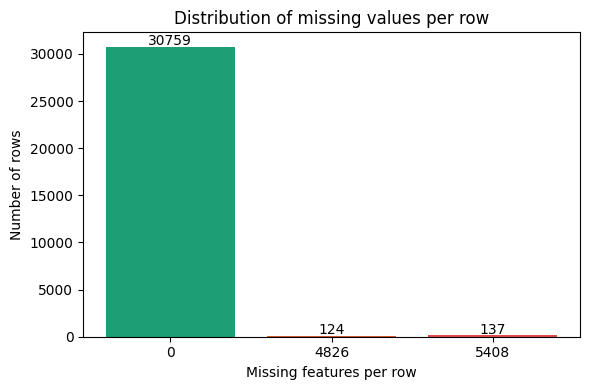

In [49]:
# Cell 8 - Bar chart of the missing-value distribution per row
import matplotlib.pyplot as plt

counts = missing_per_row.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(counts.index.astype(str), counts.values, color=["#1D9E75", "#D85A30", "#E24B4A"])
ax.set_xlabel("Missing features per row")
ax.set_ylabel("Number of rows")
ax.set_title("Distribution of missing values per row")
for i, v in enumerate(counts.values):
	ax.text(i, v + 200, str(v), ha="center")
plt.tight_layout()
plt.savefig(DATA_DIR / "missing_value_distribution.png", dpi=150)
plt.show()

In [50]:
# Cell 9 - Cleaning pipeline: drop fully-empty rows, drop rows missing the 2D block,
# drop duplicate rows, downcast dtype, drop the trailing artifact column.
# No Parquet export here yet -- that comes after label alignment (step 3).
seen_hashes = {}
duplicate_rows = []
cleaned_chunks = []

stats = {
	"rows_read": 0,
	"fully_empty_dropped": 0,
	"missing_2d_dropped": 0,
	"duplicates_dropped": 0,
	"rows_remaining": 0,
}

for chunk in pd.read_csv(DATA_FILE, na_values="?", chunksize=CHUNK_SIZE):
	chunk = chunk.rename(columns={"Unnamed: 0": "id"}).set_index("id")
	if "5409" in chunk.columns:
		chunk = chunk.drop(columns=["5409"])

	stats["rows_read"] += len(chunk)

	# drop rows with no features at all
	n_features = chunk.shape[1]
	row_missing = chunk.isna().sum(axis=1)

	fully_empty_mask = row_missing == n_features
	stats["fully_empty_dropped"] += fully_empty_mask.sum()
	chunk = chunk[~fully_empty_mask]
	row_missing = row_missing[~fully_empty_mask]

	# drop rows missing exactly the 2D feature block
	missing_2d_mask = row_missing == 4826
	stats["missing_2d_dropped"] += missing_2d_mask.sum()
	chunk = chunk[~missing_2d_mask]

	# downcast to float32 to roughly halve memory footprint
	chunk = chunk.astype("float32")

	# hash each remaining row, drop duplicates against everything seen so far
	row_hashes = pd.util.hash_pandas_object(chunk, index=False)
	keep_mask = []
	for row_id, h in zip(chunk.index, row_hashes):
		if h in seen_hashes:
			duplicate_rows.append((row_id, seen_hashes[h]))
			keep_mask.append(False)
		else:
			seen_hashes[h] = row_id
			keep_mask.append(True)

	chunk = chunk[keep_mask]
	stats["duplicates_dropped"] = len(duplicate_rows)

	cleaned_chunks.append(chunk)

df_clean = pd.concat(cleaned_chunks)
stats["rows_remaining"] = len(df_clean)

for k, v in stats.items():
	print(f"{k}: {v}")

print(f"\nMemory usage of df_clean: {df_clean.memory_usage(deep=True).sum() / 1e6:.1f} MB")

rows_read: 31020
fully_empty_dropped: 137
missing_2d_dropped: 124
duplicates_dropped: 5
rows_remaining: 30754

Memory usage of df_clean: 665.5 MB


Labels loaded: 31020
Cleaned feature rows: 30754
Feature rows with no matching label: 0

Label counts:
label
inactive    30693
active         61
Name: count, dtype: int64

Imbalance ratio: 503.2 : 1


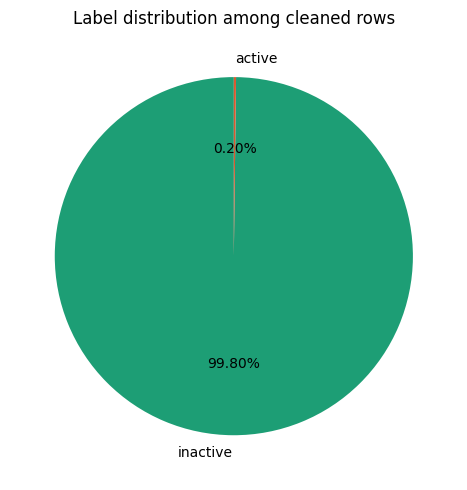

In [51]:
# Cell 10 - Load labels, align them with the cleaned feature rows (verification only,
# NOT used in the exploration/correlation analysis itself per the "don't use target" rule),
# and visualize the resulting label distribution
gt = pd.read_csv(GT_FILE)
gt = gt.rename(columns={"Unnamed: 0": "id", "5408": "label"}).set_index("id")

print(f"Labels loaded: {len(gt)}")
print(f"Cleaned feature rows: {len(df_clean)}")

# check that every remaining feature row has a matching label
missing_labels = df_clean.index.difference(gt.index)
print(f"Feature rows with no matching label: {len(missing_labels)}")

# the gt file still contains labels for rows we dropped (empty / 2D-missing / duplicates) -
# keep only the labels that correspond to rows we actually kept
gt_aligned = gt.loc[df_clean.index]
label_counts = gt_aligned["label"].value_counts()

print(f"\nLabel counts:\n{label_counts}")
print(f"\nImbalance ratio: {label_counts.max() / label_counts.min():.1f} : 1")

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(
	label_counts.values,
	labels=label_counts.index,
	autopct="%1.2f%%",
	colors=["#1D9E75", "#D85A30"],
	startangle=90,
)
ax.set_title("Label distribution among cleaned rows")
plt.tight_layout()
plt.savefig(DATA_DIR / "label_distribution.png", dpi=150)
plt.show()

In [52]:
# Cell 11 - Export the cleaned dataframe to Parquet
OUTPUT_FILE = DATA_DIR / "train_data_clean.parquet"
df_clean.to_parquet(OUTPUT_FILE)

print(f"Saved to: {OUTPUT_FILE}")
print(f"File size: {OUTPUT_FILE.stat().st_size / 1e6:.1f} MB")

Saved to: ../train_data_clean.parquet
File size: 281.4 MB


## Note: why file size changes at each stage

The same data goes through three very different size representations:

1. **Raw CSV file (~3.2 GB):** every number is stored as plain text
   (e.g. `0.46799999475479126` is 19 characters = ~19-20 bytes per value,
   including the separating comma).
2. **In-memory DataFrame after cleaning (~665.5 MB):** numbers are stored
   as `float32`, a fixed 4 bytes per value, regardless of how many digits
   the text representation had. This alone explains a ~5x size reduction.
   A small additional reduction comes from dropping 266 invalid/duplicate
   rows (~0.86% of all rows) during cleaning.
3. **Parquet file on disk (~281.4 MB):** on top of the binary float32
   representation, Parquet applies Snappy compression and a columnar
   layout, which compresses repeating patterns within each feature column.
   This gives an additional ~2.4x reduction on top of stage 2.

Text-vs-binary encoding (stage 1 -> 2) accounts for most of the overall
size reduction; compression (stage 2 -> 3) is a smaller, additional gain
on top of that.

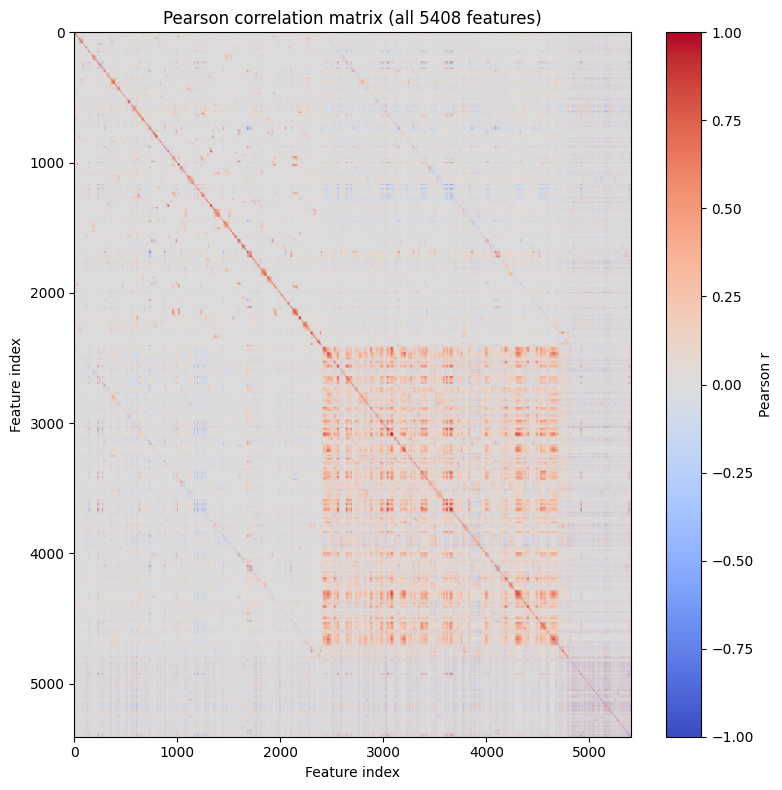

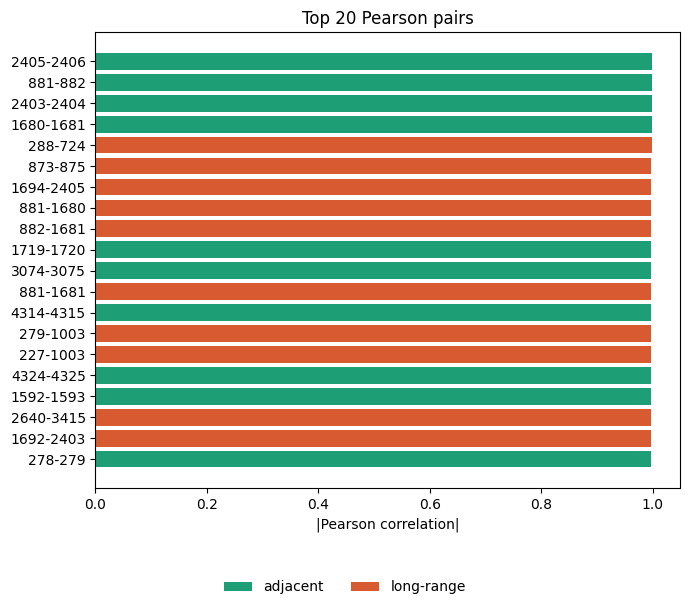

In [53]:
# Cell 12 - Load and plot the precomputed Pearson correlation matrix,
# then extract and show its own top 20 pairs (color-coded adjacent vs. long-range)
from matplotlib.patches import Patch

pearson_corr = pd.read_parquet(DATA_DIR / "pearson_corr.parquet")

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(pearson_corr.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_title("Pearson correlation matrix (all 5408 features)")
ax.set_xlabel("Feature index")
ax.set_ylabel("Feature index")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
plt.savefig(DATA_DIR / "pearson_correlation_matrix.png", dpi=150)
plt.show()

def top_pairs(corr_matrix, n=20):
	mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
	corr_values = corr_matrix.where(mask).stack()
	top = corr_values.abs().sort_values(ascending=False).head(n)
	return corr_values.loc[top.index]

def prepare_for_plot(top_series, value_name="correlation"):
	df = top_series.rename(value_name).reset_index()
	df.columns = ["feature_a", "feature_b", value_name]
	df["gap"] = (df["feature_b"].astype(int) - df["feature_a"].astype(int)).abs()
	df["pair_label"] = df["feature_a"].astype(str) + "-" + df["feature_b"].astype(str)
	df["pair_type"] = df["gap"].apply(lambda g: "adjacent" if g == 1 else "long-range")
	return df.reindex(df[value_name].abs().sort_values().index)

color_map = {"adjacent": "#1D9E75", "long-range": "#D85A30"}
legend_elems = [Patch(facecolor=c, label=l) for l, c in color_map.items()]

pearson_top = top_pairs(pearson_corr, 20)
df_plot = prepare_for_plot(pearson_top)

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(df_plot["pair_label"], df_plot["correlation"].abs(), color=df_plot["pair_type"].map(color_map))
ax.set_title("Top 20 Pearson pairs")
ax.set_xlabel("|Pearson correlation|")
fig.legend(handles=legend_elems, loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(DATA_DIR / "top_pearson_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

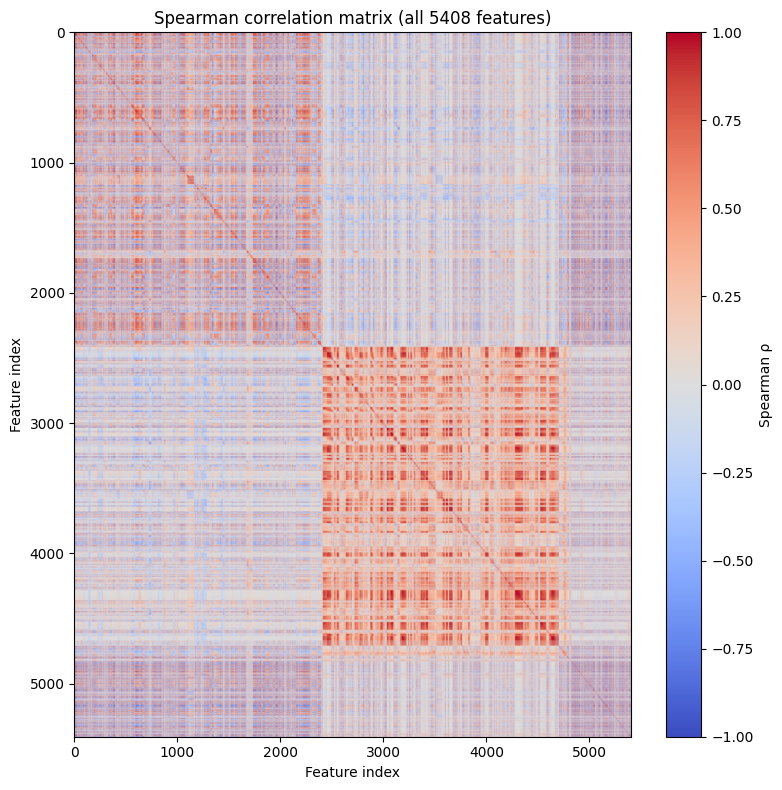

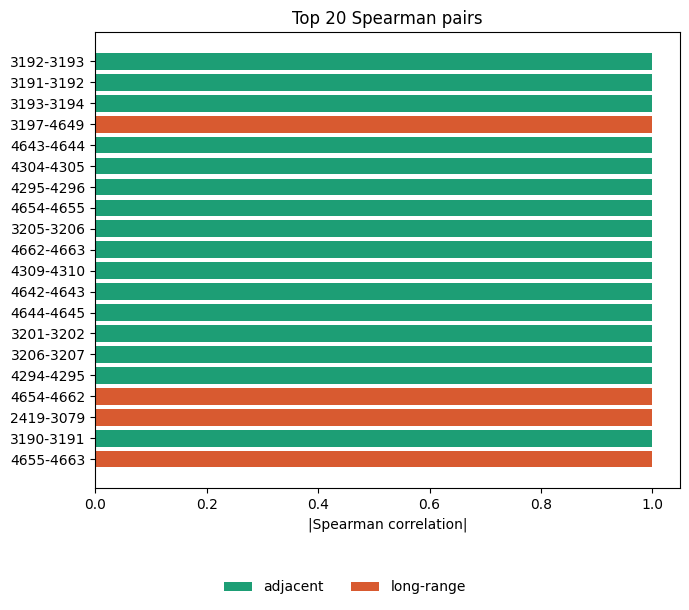

In [54]:
# Cell 13 - Load and plot the precomputed Spearman correlation matrix,
# then extract and show its own top 20 pairs
spearman_corr = pd.read_parquet(DATA_DIR / "spearman_corr.parquet")

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(spearman_corr.values, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
ax.set_title("Spearman correlation matrix (all 5408 features)")
ax.set_xlabel("Feature index")
ax.set_ylabel("Feature index")
fig.colorbar(im, ax=ax, label="Spearman ρ")
plt.tight_layout()
plt.savefig(DATA_DIR / "spearman_correlation_matrix.png", dpi=150)
plt.show()

def top_pairs(corr_matrix, n=20):
	mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
	corr_values = corr_matrix.where(mask).stack()
	top = corr_values.abs().sort_values(ascending=False).head(n)
	return corr_values.loc[top.index]

def prepare_for_plot(top_series, value_name="correlation"):
	df = top_series.rename(value_name).reset_index()
	df.columns = ["feature_a", "feature_b", value_name]
	df["gap"] = (df["feature_b"].astype(int) - df["feature_a"].astype(int)).abs()
	df["pair_label"] = df["feature_a"].astype(str) + "-" + df["feature_b"].astype(str)
	df["pair_type"] = df["gap"].apply(lambda g: "adjacent" if g == 1 else "long-range")
	return df.reindex(df[value_name].abs().sort_values().index)

color_map = {"adjacent": "#1D9E75", "long-range": "#D85A30"}
legend_elems = [Patch(facecolor=c, label=l) for l, c in color_map.items()]

spearman_top = top_pairs(spearman_corr, 20)
df_plot = prepare_for_plot(spearman_top)

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(df_plot["pair_label"], df_plot["correlation"].abs(), color=df_plot["pair_type"].map(color_map))
ax.set_title("Top 20 Spearman pairs")
ax.set_xlabel("|Spearman correlation|")
fig.legend(handles=legend_elems, loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(DATA_DIR / "top_spearman_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

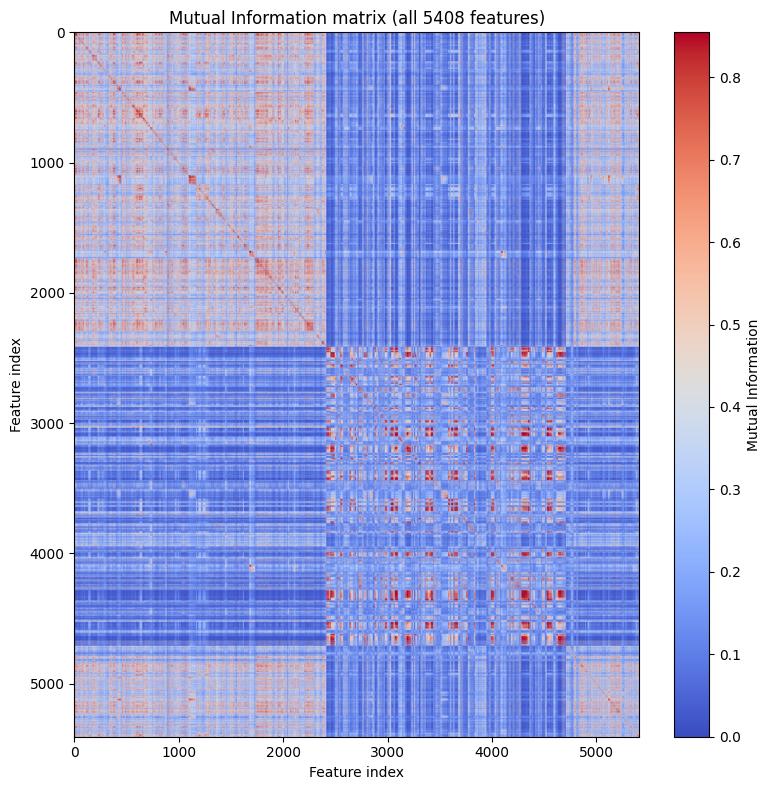

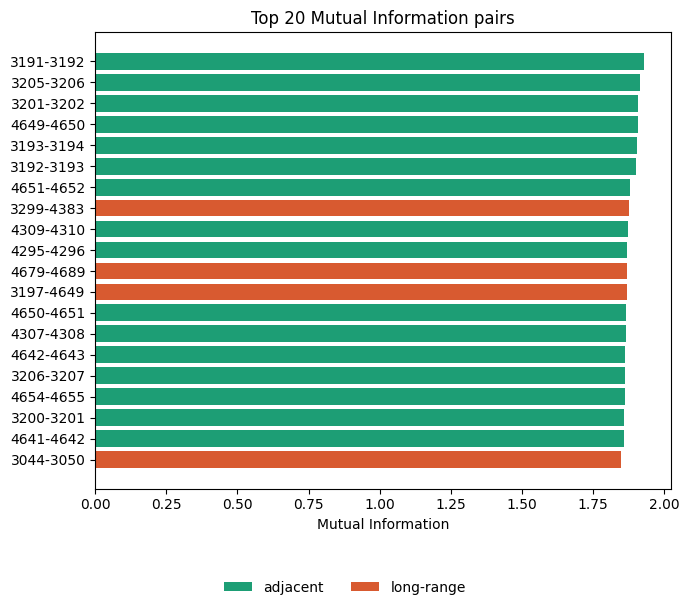

In [55]:
# Cell 14 - Load and plot the precomputed Mutual Information matrix,
# then extract and show its own top 20 pairs
mi_corr = pd.read_parquet(DATA_DIR / "mi_corr.parquet")

# MI(i,i) is the entropy of feature i, always larger than any MI(i,j) for
# i != j -- mask the diagonal so it doesn't wash out the off-diagonal scale.
mi_plot = mi_corr.values.copy()
np.fill_diagonal(mi_plot, np.nan)
vmax = np.nanpercentile(mi_plot, 99)  # cap so a few outlier pairs don't wash out the rest

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(mi_plot, cmap="coolwarm", vmin=0, vmax=vmax, aspect="auto")
ax.set_title("Mutual Information matrix (all 5408 features)")
ax.set_xlabel("Feature index")
ax.set_ylabel("Feature index")
fig.colorbar(im, ax=ax, label="Mutual Information")
plt.tight_layout()
plt.savefig(DATA_DIR / "mi_correlation_matrix.png", dpi=150)
plt.show()

def top_pairs(corr_matrix, n=20):
	# k=1 already excludes the diagonal, so no extra masking needed here
	mask = np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
	corr_values = corr_matrix.where(mask).stack()
	top = corr_values.abs().sort_values(ascending=False).head(n)
	return corr_values.loc[top.index]

def prepare_for_plot(top_series, value_name="correlation"):
	df = top_series.rename(value_name).reset_index()
	df.columns = ["feature_a", "feature_b", value_name]
	df["gap"] = (df["feature_b"].astype(int) - df["feature_a"].astype(int)).abs()
	df["pair_label"] = df["feature_a"].astype(str) + "-" + df["feature_b"].astype(str)
	df["pair_type"] = df["gap"].apply(lambda g: "adjacent" if g == 1 else "long-range")
	return df.reindex(df[value_name].abs().sort_values().index)

color_map = {"adjacent": "#1D9E75", "long-range": "#D85A30"}
legend_elems = [Patch(facecolor=c, label=l) for l, c in color_map.items()]

mi_top = top_pairs(mi_corr, 20)
df_plot = prepare_for_plot(mi_top, value_name="mutual_info")

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(df_plot["pair_label"], df_plot["mutual_info"], color=df_plot["pair_type"].map(color_map))
ax.set_title("Top 20 Mutual Information pairs")
ax.set_xlabel("Mutual Information")
fig.legend(handles=legend_elems, loc="lower center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig(DATA_DIR / "top_mi_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

## Results: top correlated pairs

**Pearson — most striking pattern:** many of the top pairs involve directly
adjacent column indices (`2405-2406`, `881-882`, `2403-2404`, `1680-1681`,
`1719-1720`, ...). This strongly suggests the features are ordered in a
meaningful spatial/sequential way -- adjacent indices likely describe
neighboring atoms/positions in the protein structure that barely differ.
Pearson also surfaces several near-perfect pairs scattered *outside* the
main correlation block entirely (e.g. `278-279`, `1592-1593`) -- likely
near-duplicate columns, candidates for feature pruning.

**Spearman & MI converge on a tighter "hot zone":** unlike Pearson, almost
all of Spearman's and MI's top 20 pairs cluster inside one narrow
sub-region, roughly indices `3190-4690` (e.g. `3191-3192`, `3192-3193`,
`3193-3194` -- four consecutive features that are nearly identical,
r > 0.998). A few "long-range" relationships are confirmed across
methods too, such as `3197-4649` (far apart in index, yet extremely
strongly correlated).

**MI-only signals:** Mutual Information additionally flags pairs that
neither Pearson nor Spearman surface at all (e.g. `3299-4383`,
`4679-4689`, `3044-3050`) -- candidates for non-monotonic dependencies
that a purely linear or monotonic measure misses by design.

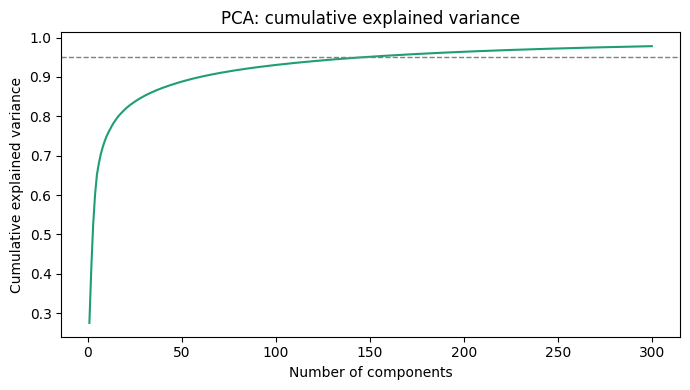

Components needed for 95% variance: 147


In [56]:
# Cell 17 - PCA: cumulative explained variance
# Note: not standardizing features here, since some columns contain large
# outliers that may themselves be the outlier-detection signal we care
# about -- standardizing could mask exactly the structure we're looking for.
# We can revisit this if the result looks dominated by 1-2 extreme features.
from sklearn.decomposition import PCA

n_components = 300
pca = PCA(n_components=n_components, svd_solver="randomized", random_state=42)
pca.fit(df_clean.values)

cumulative = np.cumsum(pca.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, n_components + 1), cumulative, color="#1D9E75")
ax.axhline(0.95, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative explained variance")
ax.set_title("PCA: cumulative explained variance")
plt.tight_layout()
plt.savefig(DATA_DIR / "pca_explained_variance.png", dpi=150)
plt.show()

n_for_95 = np.argmax(cumulative >= 0.95) + 1
print(f"Components needed for 95% variance: {n_for_95}")


## Note: what does "147 components for 95% variance" mean?

PCA finds new axes ("principal components") that are combinations of your
5408 original features, ordered by how much of the data's overall spread
(variance) they capture. The first component captures the most, the
second captures the most of what's left, and so on.

**Explained variance ratio** (per component): the fraction of the total
variance in the dataset that this one component captures.

**Cumulative explained variance**: the running total as you add more and
more components. E.g. if components 1-3 individually explain 10%, 7%, and
5%, the cumulative value after 3 components is 22%.

**What "147 components for 95% variance" means here:** instead of needing
all 5408 features to describe how the data varies, just 147 well-chosen
combinations of those features already capture 95% of that variation. In
other words, the effective complexity of the dataset is much lower than
5408 -- roughly a 37x reduction -- which is strong evidence of the
redundancy we already saw in the correlation matrices (many features
moving together). It's not extreme redundancy though (it would take far
fewer components if it were), so there's still meaningful structure beyond
just a handful of dominant patterns.

## Summary of findings

**Data structure:** 31021 rows (incl. header), 5408 features (V1-V5408 per
the original paper), split into a 2D electrostatic/surface block
(features 0-4825) and a 3D distance-based block (4826-5407). Labels live
separately in `train_gt.csv`.

**Missing values:** not random -- exactly three patterns: 30759 complete
rows, 124 rows missing the entire 2D block (3D values intact), 137 fully
empty rows. Consistent with the paper's two-stage, independently-failing
feature generation pipeline.

**Cleaning:** dropped 137 fully-empty rows, 124 rows missing the 2D block,
and 5 exact duplicate rows -> 30754 clean rows remain. Confirmed zero
remaining NaNs, infinities, constant columns, or duplicate indices.
Downcast to float32 -- verified empirically to lose no real precision
(original values were already float32-precision, just stored as float64).

**Storage:** raw CSV 3.2 GB -> in-RAM float32 665.5 MB (~4.8x, mostly
text-to-binary encoding) -> Parquet on disk 281.4 MB (~2.4x further, via
Snappy compression).

**Label distribution (cleaned rows):** 30693 inactive / 61 active
(~503:1 imbalance), consistent with the paper's reported ratio for this
type of p53 assay.

**Correlation structure:** all three methods (Pearson, Spearman, Mutual
Information) confirm one strong block (~2400-4800). Spearman and MI
further narrow this down to a tight "hot zone" (~3190-4690); Pearson
additionally surfaces near-duplicate pairs scattered outside the block
entirely. MI uniquely flags a handful of long-range pairs absent from
both correlation top-lists -- candidates for non-monotonic dependencies
that Pearson and Spearman are blind to by design. Pearson and Spearman
also reveal a negatively correlated region outside the main block
(~4500-5300).

**Dimensionality:** PCA shows 147 components capture 95% of the variance
(~37x reduction from 5408) -- meaningful redundancy, but not extreme.

Loaded train_set_p53mutant.parquet: (24603, 5408)


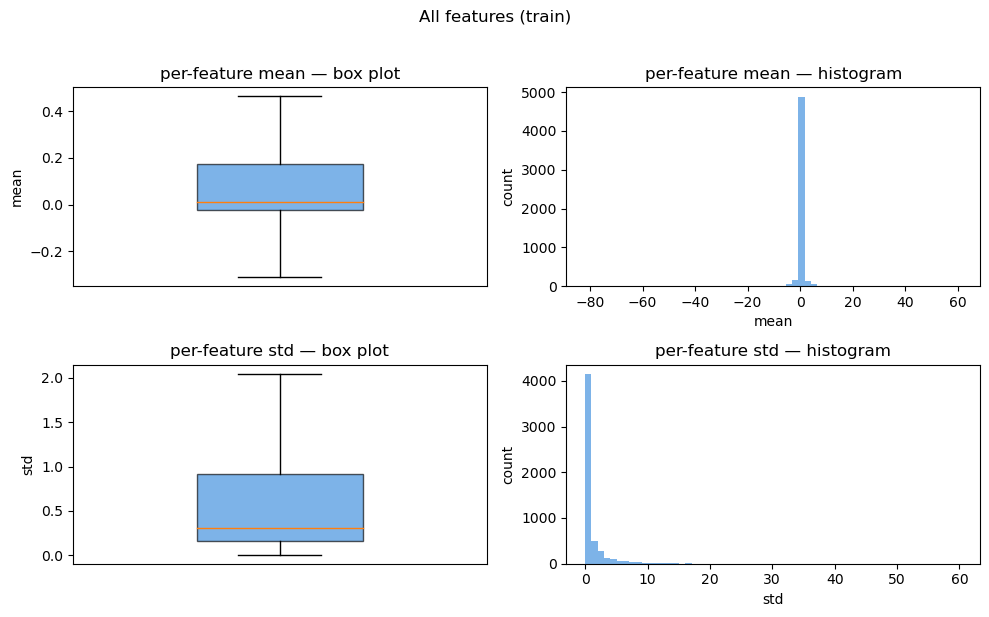


All features (train)
  mean — before: median=0.0103, spread=3.3650 | after: median=-0.0000, spread=0.0000
  std  — before: median=0.3114, max=60.2788 | after: median=1.0000, max=1.0001


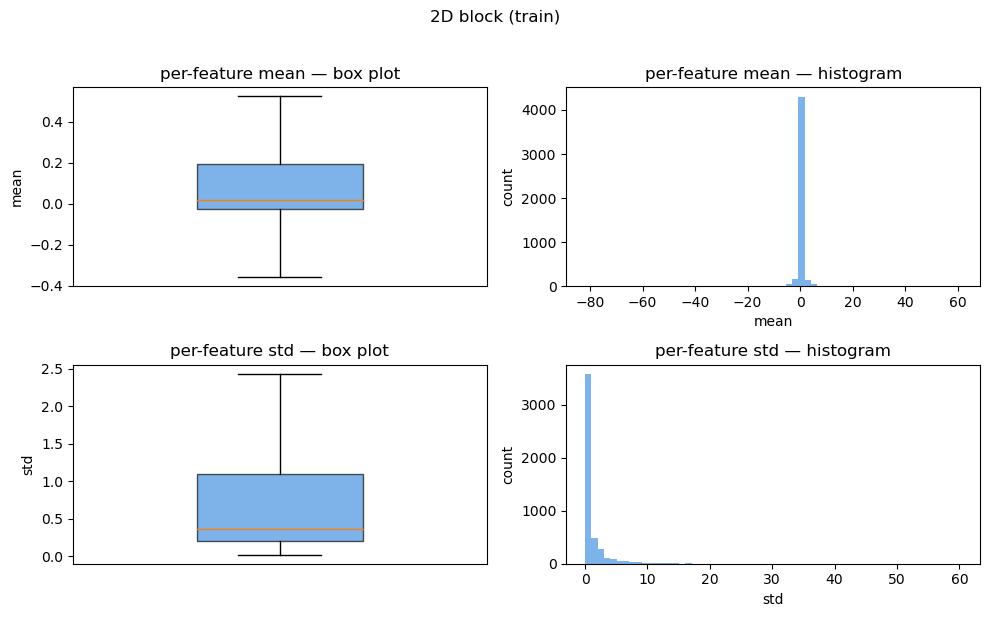


2D block (train)
  mean — before: median=0.0202, spread=3.5617 | after: median=-0.0000, spread=0.0000
  std  — before: median=0.3668, max=60.2788 | after: median=1.0000, max=1.0001


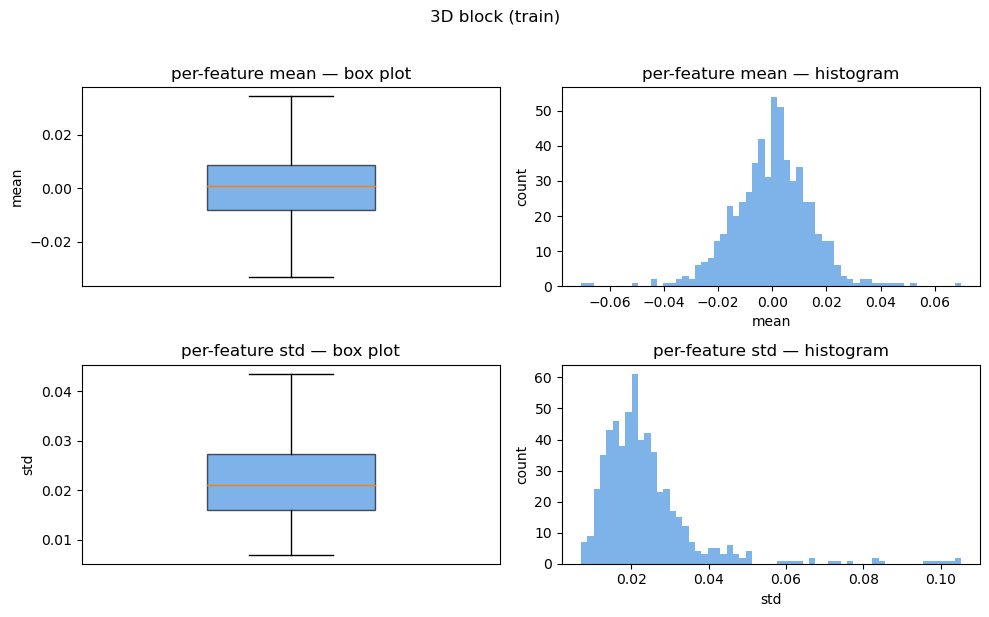


3D block (train)
  mean — before: median=0.0008, spread=0.0147 | after: median=0.0000, spread=0.0000
  std  — before: median=0.0210, max=0.1053 | after: median=1.0000, max=1.0001

--- Do we need normalization? ---
YES — scales differ a lot across columns/blocks. Try StandardScaler before PCA / LOF.

--- Summary (for slides) ---


,block,mean_median,mean_spread,std_median,std_max,std_median_after,std_max_after
0,All,0.0103,3.3650,0.3114,60.2788,1.0,1.0001
1,2D,0.0202,3.5617,0.3668,60.2788,1.0,1.0001
2,3D,0.0008,0.0147,0.0210,0.1053,1.0,1.0001


,std_ratio,2D_std_median,3D_std_median,block_gap,normalize
0,8650.3591,0.3668,0.021,0.3458,YES


In [4]:
# Normalization check — read train parquet, boxplot + histogram of raw feature scales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from pathlib import Path
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path("..")
TRAIN_FILE = PROJECT_ROOT / "train_set_p53mutant.parquet"
BLOCK_2D_END = 4826  # cols 0-4825 = 2D block, 4826+ = 3D block

df_train = pd.read_parquet(TRAIN_FILE)
print(f"Loaded {TRAIN_FILE.name}: {df_train.shape}")

scaler = StandardScaler()
df_norm = pd.DataFrame(
	scaler.fit_transform(df_train),
	index=df_train.index,
	columns=df_train.columns,
)


def per_feature_stats(df):
	return df.mean(), df.std(ddof=0)


def plot_scale_distribution(mean_before, std_before, mean_after, std_after, title, save_name):
	fig, axes = plt.subplots(2, 2, figsize=(10, 6))

	bp = axes[0, 0].boxplot(
		[mean_before.values], patch_artist=True, showfliers=False, widths=0.4,
	)
	bp["boxes"][0].set_facecolor("#378ADD")
	bp["boxes"][0].set_alpha(0.65)
	axes[0, 0].set_title("per-feature mean — box plot")
	axes[0, 0].set_ylabel("mean")
	axes[0, 0].set_xticks([])

	axes[0, 1].hist(mean_before, bins=60, color="#378ADD", alpha=0.65)
	axes[0, 1].set_title("per-feature mean — histogram")
	axes[0, 1].set_xlabel("mean")
	axes[0, 1].set_ylabel("count")

	bp = axes[1, 0].boxplot(
		[std_before.values], patch_artist=True, showfliers=False, widths=0.4,
	)
	bp["boxes"][0].set_facecolor("#378ADD")
	bp["boxes"][0].set_alpha(0.65)
	axes[1, 0].set_title("per-feature std — box plot")
	axes[1, 0].set_ylabel("std")
	axes[1, 0].set_xticks([])

	axes[1, 1].hist(std_before, bins=60, color="#378ADD", alpha=0.65)
	axes[1, 1].set_title("per-feature std — histogram")
	axes[1, 1].set_xlabel("std")
	axes[1, 1].set_ylabel("count")

	fig.suptitle(title, y=1.02)
	plt.tight_layout()
	plt.savefig(PROJECT_ROOT / save_name, dpi=150, bbox_inches="tight")
	plt.show()

	print(f"\n{title}")
	print(f"  mean — before: median={mean_before.median():.4f}, spread={mean_before.std():.4f} | "
	      f"after: median={mean_after.median():.4f}, spread={mean_after.std():.4f}")
	print(f"  std  — before: median={std_before.median():.4f}, max={std_before.max():.4f} | "
	      f"after: median={std_after.median():.4f}, max={std_after.max():.4f}")


mean_b, std_b = per_feature_stats(df_train)
mean_a, std_a = per_feature_stats(df_norm)
plot_scale_distribution(mean_b, std_b, mean_a, std_a, "All features (train)", "norm_check_all.png")

raw_2d, norm_2d = df_train.iloc[:, :BLOCK_2D_END], df_norm.iloc[:, :BLOCK_2D_END]
mean_b_2d, std_b_2d = per_feature_stats(raw_2d)
mean_a_2d, std_a_2d = per_feature_stats(norm_2d)
plot_scale_distribution(mean_b_2d, std_b_2d, mean_a_2d, std_a_2d, "2D block (train)", "norm_check_2d.png")

raw_3d, norm_3d = df_train.iloc[:, BLOCK_2D_END:], df_norm.iloc[:, BLOCK_2D_END:]
mean_b_3d, std_b_3d = per_feature_stats(raw_3d)
mean_a_3d, std_a_3d = per_feature_stats(norm_3d)
plot_scale_distribution(mean_b_3d, std_b_3d, mean_a_3d, std_a_3d, "3D block (train)", "norm_check_3d.png")

std_ratio = std_b.max() / std_b[std_b > 0].min()
block_gap = abs(std_b_2d.median() - std_b_3d.median())
need_norm = std_ratio > 20 or block_gap > 0.05 * max(std_b_2d.median(), std_b_3d.median())
print("\n--- Do we need normalization? ---")
if need_norm:
	print("YES — scales differ a lot across columns/blocks. Try StandardScaler before PCA / LOF.")
else:
	print("PROBABLY NOT REQUIRED — scales are already fairly homogeneous.")

summary_table = pd.DataFrame(
	[
		{
			"block": "All",
			"mean_median": mean_b.median(),
			"mean_spread": mean_b.std(),
			"std_median": std_b.median(),
			"std_max": std_b.max(),
			"std_median_after": std_a.median(),
			"std_max_after": std_a.max(),
		},
		{
			"block": "2D",
			"mean_median": mean_b_2d.median(),
			"mean_spread": mean_b_2d.std(),
			"std_median": std_b_2d.median(),
			"std_max": std_b_2d.max(),
			"std_median_after": std_a_2d.median(),
			"std_max_after": std_a_2d.max(),
		},
		{
			"block": "3D",
			"mean_median": mean_b_3d.median(),
			"mean_spread": mean_b_3d.std(),
			"std_median": std_b_3d.median(),
			"std_max": std_b_3d.max(),
			"std_median_after": std_a_3d.median(),
			"std_max_after": std_a_3d.max(),
		},
	]
).round(4)

global_table = pd.DataFrame(
	[
		{
			"std_ratio": std_ratio,
			"2D_std_median": std_b_2d.median(),
			"3D_std_median": std_b_3d.median(),
			"block_gap": block_gap,
			"normalize": "YES" if need_norm else "NO",
		}
	]
).round(4)

print("\n--- Summary (for slides) ---")
display(summary_table)
display(global_table)

summary_table.to_csv(PROJECT_ROOT / "norm_check_summary.csv", index=False)
global_table.to_csv(PROJECT_ROOT / "norm_check_global.csv", index=False)

In [7]:
# Highest per-feature std — column 4130 (V4131)
FEAT_IDX = 4130
col = df_train.iloc[:, FEAT_IDX]
feat_name = df_train.columns[FEAT_IDX]

feat_stats_table = pd.DataFrame(
	{
		"stat": [
			"column_name", "column_index", "block",
			"count", "mean", "std", "min", "25%", "50%", "75%", "max",
		],
		"value": [
			feat_name,
			FEAT_IDX,
			"2D" if FEAT_IDX < BLOCK_2D_END else "3D",
			int(col.count()),
			round(col.mean(), 4),
			round(col.std(ddof=0), 4),
			round(col.min(), 4),
			round(col.quantile(0.25), 4),
			round(col.median(), 4),
			round(col.quantile(0.75), 4),
			round(col.max(), 4),
		],
	}
)

print(f"Feature with highest std across train set (std_max = {std_b.max():.4f})")
display(feat_stats_table)

Feature with highest std across train set (std_max = 60.2788)


,stat,value
0,column_name,4130
1,column_index,4130
2,block,2D
3,count,24603
4,mean,27.586399
5,std,60.2788
6,min,-38.53
7,25%,2.9725
8,50%,6.62
9,75%,12.2675
